Import Libraries and Set Random Seed

In [16]:
import warnings
warnings.filterwarnings("default")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
from scipy.stats import chi2_contingency, mannwhitneyu
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.diagnostic import lilliefors

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

SEED = 2026
ALPHA = 0.05

np.random.seed(SEED)

print("Libraries imported.")
print("Random seed:", SEED)
print("Significance level:", ALPHA)

Libraries imported.
Random seed: 2026
Significance level: 0.05


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Load Application and Credit-History Datasets

In [17]:
import os
import pandas as pd

required_files = ["application_record.csv", "credit_record.csv"]


for filename in required_files:
    if not os.path.exists(filename):
        raise FileNotFoundError(
            f"{filename} not found. Check the Colab Files panel "
            "and update the file path if necessary."
        )


app_raw = pd.read_csv(
    "application_record.csv",
    dtype={"ID": "string"},
    low_memory=False
)

credit_raw = pd.read_csv(
    "credit_record.csv",
    dtype={
        "ID": "string",
        "MONTHS_BALANCE": "string",
        "STATUS": "string"
    },
    low_memory=False
)


print("APPLICATION DATA")
print("Shape:", app_raw.shape)
print("Unique IDs:", app_raw["ID"].nunique())
print("Columns:", app_raw.columns.tolist())

print("\nCREDIT HISTORY DATA")
print("Shape:", credit_raw.shape)
print("Unique IDs:", credit_raw["ID"].nunique())
print("Columns:", credit_raw.columns.tolist())

print("\nMissing values in application data:",
      app_raw.isna().sum().sum())

print("Missing values in credit data:",
      credit_raw.isna().sum().sum())

APPLICATION DATA
Shape: (438557, 18)
Unique IDs: 438510
Columns: ['ID', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'FLAG_MOBIL', 'FLAG_WORK_PHONE', 'FLAG_PHONE', 'FLAG_EMAIL', 'OCCUPATION_TYPE', 'CNT_FAM_MEMBERS']

CREDIT HISTORY DATA
Shape: (1048575, 3)
Unique IDs: 45985
Columns: ['ID', 'MONTHS_BALANCE', 'STATUS']

Missing values in application data: 134203
Missing values in credit data: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Inspect Missing Values and Duplicate Records

In [18]:

missing_summary = pd.DataFrame({
    "Missing count": app_raw.isna().sum(),
    "Missing percent": app_raw.isna().mean() * 100
}).sort_values("Missing percent", ascending=False)

display(missing_summary.round(2))


print("Exact duplicate application rows:",
      app_raw.duplicated().sum())

print("Exact duplicate credit rows:",
      credit_raw.duplicated().sum())


print("Application rows with repeated IDs:",
      app_raw["ID"].duplicated(keep=False).sum())

print("Number of repeated application IDs:",
      app_raw.loc[
          app_raw["ID"].duplicated(keep=False), "ID"
      ].nunique())


print("Repeated IDs in credit history:",
      credit_raw["ID"].duplicated().sum())

,Missing count,Missing percent
OCCUPATION_TYPE,134203,30.6
ID,0,0.0
CODE_GENDER,0,0.0
FLAG_OWN_CAR,0,0.0
CNT_CHILDREN,0,0.0
FLAG_OWN_REALTY,0,0.0
NAME_INCOME_TYPE,0,0.0
NAME_EDUCATION_TYPE,0,0.0
NAME_FAMILY_STATUS,0,0.0
AMT_INCOME_TOTAL,0,0.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Exact duplicate application rows: 0
Exact duplicate credit rows: 0
Application rows with repeated IDs: 94
Number of repeated application IDs: 47
Repeated IDs in credit history: 1002590


Clean and Validate Application and Credit-History Datasets

In [19]:
app = app_raw.copy()
credit = credit_raw.copy()


app_exact_removed = int(app.duplicated().sum())
credit_exact_removed = int(credit.duplicated().sum())

app = app.drop_duplicates().copy()
credit = credit.drop_duplicates().copy()

print("Exact duplicate application rows removed:", app_exact_removed)
print("Exact duplicate credit rows removed:", credit_exact_removed)


print("\nMissing application IDs:", app["ID"].isna().sum())
print("Missing credit IDs:", credit["ID"].isna().sum())

app = app.dropna(subset=["ID"]).copy()
credit = credit.dropna(subset=["ID"]).copy()


conflict_mask = app.duplicated("ID", keep=False)
conflict_ids = set(app.loc[conflict_mask, "ID"])

credit_ids = set(credit["ID"].unique())
conflicts_in_credit = conflict_ids & credit_ids

print("\nConflicting application IDs:", len(conflict_ids))
print("Conflicting IDs also present in credit data:",
      len(conflicts_in_credit))

if conflicts_in_credit:
    print(
        "WARNING: Some conflicting IDs have credit histories. "
        "Do not merge until these are investigated."
    )
    display(
        app[app["ID"].isin(conflicts_in_credit)]
        .sort_values("ID")
    )
else:

    app = app[~app["ID"].isin(conflict_ids)].copy()

assert app["ID"].is_unique, "Application IDs must now be unique."


credit["MONTHS_BALANCE"] = pd.to_numeric(
    credit["MONTHS_BALANCE"], errors="coerce"
)

credit["STATUS"] = credit["STATUS"].str.strip()

invalid_month = credit["MONTHS_BALANCE"].isna()
invalid_status = credit["STATUS"].isna() | credit["STATUS"].eq("")

print("\nRows with invalid month:", invalid_month.sum())
print("Rows with missing/blank status:", invalid_status.sum())


credit = credit[
    (~invalid_month) & (~invalid_status)
].copy()


credit = credit[
    credit["MONTHS_BALANCE"] % 1 == 0
].copy()

credit["MONTHS_BALANCE"] = credit["MONTHS_BALANCE"].astype(int)


valid_statuses = {"0", "1", "2", "3", "4", "5", "C", "X"}
unexpected_statuses = set(credit["STATUS"].unique()) - valid_statuses

print("Unexpected status values:", unexpected_statuses)

if unexpected_statuses:
    raise ValueError(
        "Investigate unexpected status values before continuing."
    )


duplicate_month_mask = credit.duplicated(
    subset=["ID", "MONTHS_BALANCE"], keep=False
)

print("Rows in repeated ID-month groups:",
      duplicate_month_mask.sum())

if duplicate_month_mask.any():
    display(
        credit.loc[duplicate_month_mask]
        .sort_values(["ID", "MONTHS_BALANCE"])
        .head(30)
    )

    raise ValueError(
        "Repeated ID-month keys need investigation before merging."
    )

print("\nApplication IDs unique:", app["ID"].is_unique)
print("Credit ID-month keys unique:",
      not credit.duplicated(["ID", "MONTHS_BALANCE"]).any())

Exact duplicate application rows removed: 0
Exact duplicate credit rows removed: 0

Missing application IDs: 0
Missing credit IDs: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



Conflicting application IDs: 47
Conflicting IDs also present in credit data: 0

Rows with invalid month: 0
Rows with missing/blank status: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Unexpected status values: set()
Rows in repeated ID-month groups: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



Application IDs unique: True
Credit ID-month keys unique: True


Define the Dataset Data Dictionary

In [20]:
data_dictionary = pd.DataFrame([
    ["ID", "Identifier", "Applicant identifier", "Not a predictor"],
    ["CODE_GENDER", "Nominal", "Recorded gender category", "Category"],
    ["FLAG_OWN_CAR", "Nominal/binary", "Owns a car", "Y/N"],
    ["FLAG_OWN_REALTY", "Nominal/binary", "Owns property", "Y/N"],
    ["CNT_CHILDREN", "Discrete", "Number of children", "Count"],
    ["AMT_INCOME_TOTAL", "Continuous", "Recorded annual income", "Dataset currency"],
    ["NAME_INCOME_TYPE", "Nominal", "Income/employment category", "Category"],
    ["NAME_EDUCATION_TYPE", "Ordinal categorical", "Education category", "Category"],
    ["NAME_FAMILY_STATUS", "Nominal", "Family/marital status", "Category"],
    ["NAME_HOUSING_TYPE", "Nominal", "Housing arrangement", "Category"],
    ["DAYS_BIRTH", "Continuous-derived", "Days before application birth reference", "Days; negative values"],
    ["DAYS_EMPLOYED", "Continuous-derived", "Employment duration field", "Days; sentinel possible"],
    ["OCCUPATION_TYPE", "Nominal", "Occupation category", "Category"],
    ["CNT_FAM_MEMBERS", "Discrete", "Number of family members", "Count"],
    ["MONTHS_BALANCE", "Discrete", "Month relative to record reference", "Integer month index"],
    ["STATUS", "Categorical", "Monthly credit status", "0–5, C, X"]
], columns=["Feature", "Type", "Real-world interpretation", "Unit/range"])

display(data_dictionary)

,Feature,Type,Real-world interpretation,Unit/range
0,ID,Identifier,Applicant identifier,Not a predictor
1,CODE_GENDER,Nominal,Recorded gender category,Category
2,FLAG_OWN_CAR,Nominal/binary,Owns a car,Y/N
3,FLAG_OWN_REALTY,Nominal/binary,Owns property,Y/N
4,CNT_CHILDREN,Discrete,Number of children,Count
5,AMT_INCOME_TOTAL,Continuous,Recorded annual income,Dataset currency
6,NAME_INCOME_TYPE,Nominal,Income/employment category,Category
7,NAME_EDUCATION_TYPE,Ordinal categorical,Education category,Category
8,NAME_FAMILY_STATUS,Nominal,Family/marital status,Category
9,NAME_HOUSING_TYPE,Nominal,Housing arrangement,Category


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Match Applicant IDs and Merge Monthly Credit-History Records

In [21]:
app_ids = set(app["ID"].unique())
credit_ids = set(credit["ID"].unique())

matched_ids = app_ids & credit_ids

print("Unique application IDs:", len(app_ids))
print("Unique credit-history IDs:", len(credit_ids))
print("Matched applicants:", len(matched_ids))
print("Unmatched application IDs:", len(app_ids - credit_ids))
print("Unmatched credit-history IDs:", len(credit_ids - app_ids))


merged = credit.merge(
    app,
    on="ID",
    how="inner",
    validate="many_to_one"
)

print("\nMERGED MONTHLY DATA")
print("Rows:", len(merged))
print("Columns:", len(merged.columns))
print("Unique applicants:", merged["ID"].nunique())
print("Credit rows before merge:", len(credit))
print("Matched credit rows:", len(merged))

assert len(merged) <= len(credit), (
    "An inner join with unique application IDs cannot produce "
    "more rows than the credit table. Recheck the input files."
)

print(
    "Monthly credit records retained:",
    f"{100 * len(merged) / len(credit):.2f}%"
)

Unique application IDs: 438463
Unique credit-history IDs: 45985
Matched applicants: 36457
Unmatched application IDs: 402006
Unmatched credit-history IDs: 9528


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



MERGED MONTHLY DATA
Rows: 777715
Columns: 20
Unique applicants: 36457
Credit rows before merge: 1048575
Matched credit rows: 777715
Monthly credit records retained: 74.17%


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Feature Engineering

In [22]:
merged["AGE_YEARS"] = -merged["DAYS_BIRTH"] / 365.25


merged["EMPLOYMENT_YEARS"] = np.where(
    merged["DAYS_EMPLOYED"] < 0,
    -merged["DAYS_EMPLOYED"] / 365.25,
    np.nan
)

print("Missing values in merged data:")
display(
    merged.isna().sum()
    .sort_values(ascending=False)
    .to_frame("Missing count")
    .head(20)
)

print("\nDAYS_EMPLOYED positive sentinel values:",
      (merged["DAYS_EMPLOYED"] == 365243).sum())

print("Nonpositive income values:",
      (merged["AMT_INCOME_TOTAL"] <= 0).sum())

print("\nNumeric summaries:")



Missing values in merged data:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Missing count
OCCUPATION_TYPE,240048
EMPLOYMENT_YEARS,127972
STATUS,0
CODE_GENDER,0
ID,0
MONTHS_BALANCE,0
FLAG_OWN_REALTY,0
FLAG_OWN_CAR,0
CNT_CHILDREN,0
AMT_INCOME_TOTAL,0



DAYS_EMPLOYED positive sentinel values: 127972
Nonpositive income values: 0

Numeric summaries:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**Create Applicant-Level Dataset and Define Delinquency**

In [23]:
merged["IS_ACTIVE_MONTH"] = merged["STATUS"].isin(
    ["0", "1", "2", "3", "4", "5"]
)

merged["IS_SERIOUS_DELINQUENCY"] = merged["STATUS"].isin(
    ["2", "3", "4", "5"]
)


merged["MONTHLY_SERIOUS_DELINQUENCY"] = np.where(
    merged["IS_ACTIVE_MONTH"],
    merged["IS_SERIOUS_DELINQUENCY"].astype(int),
    np.nan
)


credit_summary = (
    merged.groupby("ID")
    .agg(
        total_recorded_months=("STATUS", "size"),
        active_credit_months=("IS_ACTIVE_MONTH", "sum"),
        serious_delinquent_months=("IS_SERIOUS_DELINQUENCY", "sum"),
        first_observed_month=("MONTHS_BALANCE", "min"),
        last_observed_month=("MONTHS_BALANCE", "max")
    )
    .reset_index()
)


credit_summary["ELIGIBLE"] = (
    credit_summary["active_credit_months"] > 0
)

credit_summary["EVER_SERIOUS_DELINQUENCY"] = (
    credit_summary["serious_delinquent_months"] > 0
).astype(int)


applicant_all = credit_summary.merge(
    app,
    on="ID",
    how="left",
    validate="one_to_one"
)

applicant_all = applicant_all[
    applicant_all["ELIGIBLE"]
].copy()


applicant_all["EVER_SERIOUS_DELINQUENCY"] = (
    applicant_all["EVER_SERIOUS_DELINQUENCY"].astype(int)
)

print("Matched applicants before eligibility filter:",
      credit_summary["ID"].nunique())

print("Eligible applicants for applicant-level inference:",
      len(applicant_all))

print("\nApplicant-level outcome counts:")
display(
    applicant_all["EVER_SERIOUS_DELINQUENCY"]
    .value_counts()
    .rename(index={0: "No observed serious delinquency",
                   1: "Ever observed serious delinquency"})
    .to_frame("Applicants")
)

print("\nMonthly outcome counts:")
display(
    merged["MONTHLY_SERIOUS_DELINQUENCY"]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("Monthly observations")
)

Matched applicants before eligibility filter: 36457
Eligible applicants for applicant-level inference: 32002

Applicant-level outcome counts:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Applicants
EVER_SERIOUS_DELINQUENCY,
No observed serious delinquency,31386
Ever observed serious delinquency,616



Monthly outcome counts:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Monthly observations
MONTHLY_SERIOUS_DELINQUENCY,
0.0,299401
1.0,2828
NaN,475486


Check Dataset Dimensions and Encoding Size

In [24]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder
from scipy import sparse

CELL_THRESHOLD = 3_000_000


monthly_categorical = [
    "CODE_GENDER",
    "FLAG_OWN_CAR",
    "FLAG_OWN_REALTY",
    "NAME_INCOME_TYPE",
    "NAME_EDUCATION_TYPE",
    "NAME_FAMILY_STATUS",
    "NAME_HOUSING_TYPE",
    "OCCUPATION_TYPE",
    "STATUS"
]


applicant_categorical = [
    "CODE_GENDER",
    "FLAG_OWN_CAR",
    "FLAG_OWN_REALTY",
    "NAME_INCOME_TYPE",
    "NAME_EDUCATION_TYPE",
    "NAME_FAMILY_STATUS",
    "NAME_HOUSING_TYPE",
    "OCCUPATION_TYPE"
]




dataset_stages = [
    ("Raw application dataset", app_raw),
    ("Cleaned application dataset", app),
    ("Raw credit-history dataset", credit_raw),
    ("Cleaned credit-history dataset", credit),
    ("Linked/engineered monthly dataset", merged),
    ("Eligible applicant-level dataset", applicant_all)
]

stage_results = []

print("=" * 70)
print("DATASET DIMENSIONS BEFORE ONE-HOT ENCODING")
print("=" * 70)

for name, df in dataset_stages:
    rows, columns = df.shape

    result = {
        "Dataset stage": name,
        "Rows": rows,
        "Columns": columns,
        "Unique applicants": df["ID"].nunique(),
        "Missing cells": int(df.isna().sum().sum())
    }

    stage_results.append(result)

    print(f"\n{name}")
    print(f"Rows: {rows:,}")
    print(f"Columns: {columns:,}")
    print(f"Unique IDs: {df['ID'].nunique():,}")
    print(f"Missing cells: {df.isna().sum().sum():,}")

stage_audit = pd.DataFrame(stage_results)

print("\nDATASET STAGE SUMMARY")
display(stage_audit)






def encode_for_audit(df, categorical_cols, dataset_name):

    data = df.copy()


    excluded = {"ID", "EVER_SERIOUS_DELINQUENCY"}

    feature_cols = [
        col for col in data.columns
        if col not in excluded
    ]


    categorical_cols = [
        col for col in categorical_cols
        if col in feature_cols
    ]


    numeric_cols = [
        col for col in feature_cols
        if col not in categorical_cols
        and pd.api.types.is_numeric_dtype(data[col])
    ]


    unhandled_cols = [
        col for col in feature_cols
        if col not in categorical_cols
        and col not in numeric_cols
    ]

    if unhandled_cols:
        raise ValueError(
            f"{dataset_name}: unhandled feature columns: "
            f"{unhandled_cols}"
        )


    X_cat = (
        data[categorical_cols]
        .astype("string")
        .fillna("Missing")
    )

    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    )

    X_encoded_cat = encoder.fit_transform(X_cat)

    X_numeric = data[numeric_cols].apply(
        pd.to_numeric,
        errors="coerce"
    )

    X_numeric_sparse = sparse.csr_matrix(
        X_numeric.fillna(0).to_numpy(dtype=float)
    )


    X_encoded = sparse.hstack(
        [X_numeric_sparse, X_encoded_cat],
        format="csr"
    )

    n_rows, n_features = X_encoded.shape
    n_cells = n_rows * n_features

    result = {
        "Dataset": dataset_name,
        "Rows": n_rows,
        "Original predictor columns": len(feature_cols),
        "Numeric features retained": len(numeric_cols),
        "Categorical features encoded": len(categorical_cols),
        "One-hot columns": X_encoded_cat.shape[1],
        "Total encoded features": n_features,
        "Total cells": n_cells,
        "Meets 3M requirement": n_cells >= CELL_THRESHOLD
    }

    print(f"\n{'-' * 60}")
    print(dataset_name)
    print(f"{'-' * 60}")
    print(f"Rows: {n_rows:,}")
    print(f"Predictor columns before encoding: {len(feature_cols):,}")
    print(f"Numeric features retained: {len(numeric_cols):,}")
    print(f"Categorical features encoded: {len(categorical_cols):,}")
    print(f"One-hot encoded columns: {X_encoded_cat.shape[1]:,}")
    print(f"Total encoded features: {n_features:,}")
    print(f"Total cells: {n_cells:,}")
    print(
        "Meets 3-million-cell requirement:",
        n_cells >= CELL_THRESHOLD
    )

    return X_encoded, result




X_applicant_encoded, applicant_audit = encode_for_audit(
    df=applicant_all,
    categorical_cols=applicant_categorical,
    dataset_name="Eligible applicant-level dataset"
)



X_monthly_encoded, monthly_audit = encode_for_audit(
    df=merged,
    categorical_cols=monthly_categorical,
    dataset_name="Linked/engineered monthly dataset"
)




encoding_audit = pd.DataFrame([
    applicant_audit,
    monthly_audit
])

print("\nFINAL ENCODING AUDIT")
display(encoding_audit)




print("\n3-MILLION-CELL REQUIREMENT CHECK")

for result in [applicant_audit, monthly_audit]:

    rows = result["Rows"]
    features = result["Total encoded features"]
    cells = result["Total cells"]

    print(
        f"\n{result['Dataset']}: "
        f"{rows:,} x {features:,} = {cells:,} cells"
    )

    print(
        "Requirement met:",
        cells >= CELL_THRESHOLD
    )

DATASET DIMENSIONS BEFORE ONE-HOT ENCODING

Raw application dataset
Rows: 438,557
Columns: 18
Unique IDs: 438,510
Missing cells: 134,203

Cleaned application dataset
Rows: 438,463
Columns: 18
Unique IDs: 438,463
Missing cells: 134,177

Raw credit-history dataset
Rows: 1,048,575
Columns: 3
Unique IDs: 45,985
Missing cells: 0

Cleaned credit-history dataset
Rows: 1,048,575
Columns: 3
Unique IDs: 45,985
Missing cells: 0

Linked/engineered monthly dataset
Rows: 777,715
Columns: 25
Unique IDs: 36,457
Missing cells: 843,506

Eligible applicant-level dataset
Rows: 32,002
Columns: 25
Unique IDs: 32,002
Missing cells: 9,961

DATASET STAGE SUMMARY


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Dataset stage,Rows,Columns,Unique applicants,Missing cells
0,Raw application dataset,438557,18,438510,134203
1,Cleaned application dataset,438463,18,438463,134177
2,Raw credit-history dataset,1048575,3,45985,0
3,Cleaned credit-history dataset,1048575,3,45985,0
4,Linked/engineered monthly dataset,777715,25,36457,843506
5,Eligible applicant-level dataset,32002,25,32002,9961



------------------------------------------------------------
Eligible applicant-level dataset
------------------------------------------------------------
Rows: 32,002
Predictor columns before encoding: 23
Numeric features retained: 15
Categorical features encoded: 8
One-hot encoded columns: 46
Total encoded features: 61
Total cells: 1,952,122
Meets 3-million-cell requirement: False


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



------------------------------------------------------------
Linked/engineered monthly dataset
------------------------------------------------------------
Rows: 777,715
Predictor columns before encoding: 24
Numeric features retained: 15
Categorical features encoded: 9
One-hot encoded columns: 54
Total encoded features: 69
Total cells: 53,662,335
Meets 3-million-cell requirement: True

FINAL ENCODING AUDIT


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Dataset,Rows,Original predictor columns,Numeric features retained,Categorical features encoded,One-hot columns,Total encoded features,Total cells,Meets 3M requirement
0,Eligible applicant-level dataset,32002,23,15,8,46,61,1952122,False
1,Linked/engineered monthly dataset,777715,24,15,9,54,69,53662335,True



3-MILLION-CELL REQUIREMENT CHECK

Eligible applicant-level dataset: 32,002 x 61 = 1,952,122 cells
Requirement met: False

Linked/engineered monthly dataset: 777,715 x 69 = 53,662,335 cells
Requirement met: True


Split Data and Explore Applicant Characteristics

In [25]:


analysis_df = applicant_all.dropna(
    subset=["EVER_SERIOUS_DELINQUENCY"]
).copy()

analysis_df["EVER_SERIOUS_DELINQUENCY"] = (
    analysis_df["EVER_SERIOUS_DELINQUENCY"].astype(int)
)

explore_df, confirm_df = train_test_split(
    analysis_df,
    test_size=0.20,
    random_state=2026,
    stratify=analysis_df["EVER_SERIOUS_DELINQUENCY"]
)

print("Exploration set:", explore_df.shape)
print("Confirmation set:", confirm_df.shape)



explore_df = explore_df.copy()
explore_df["AGE_YEARS"] = (
    -pd.to_numeric(explore_df["DAYS_BIRTH"], errors="coerce") / 365.25
)


print("\nNumeric summaries — exploration subset:")
display(
    explore_df[
        ["AMT_INCOME_TOTAL", "AGE_YEARS",
         "CNT_CHILDREN", "CNT_FAM_MEMBERS"]
    ].describe(percentiles=[.01, .25, .5, .75, .99]).T
)


def iqr_outlier_summary(series):
    x = series.dropna()
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = (x < lower) | (x > upper)

    return pd.Series({
        "Lower fence": lower,
        "Upper fence": upper,
        "Potential outlier count": outliers.sum(),
        "Potential outlier percent": 100 * outliers.mean()
    })

display(pd.DataFrame({
    col: iqr_outlier_summary(explore_df[col])
    for col in ["AMT_INCOME_TOTAL", "AGE_YEARS",
                "CNT_CHILDREN", "CNT_FAM_MEMBERS"]
}).T.round(2))



Exploration set: (25601, 25)
Confirmation set: (6401, 25)

Numeric summaries — exploration subset:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,count,mean,std,min,1%,25%,50%,75%,99%,max
AMT_INCOME_TOTAL,25601.0,185996.794637,100855.469324,27000.00000,54000.000000,121500.000000,157500.000000,225000.000000,560250.000000,1.575000e+06
AGE_YEARS,25601.0,43.800104,11.510878,21.09514,23.969884,34.097194,42.781656,53.327858,66.206708,6.886242e+01
CNT_CHILDREN,25601.0,0.431585,0.743367,0.00000,0.000000,0.000000,0.000000,1.000000,3.000000,1.900000e+01
CNT_FAM_MEMBERS,25601.0,2.200852,0.910898,1.00000,1.000000,2.000000,2.000000,3.000000,5.000000,2.000000e+01


,Lower fence,Upper fence,Potential outlier count,Potential outlier percent
AMT_INCOME_TOTAL,-33750.00,380250.00,1051.0,4.11
AGE_YEARS,5.25,82.17,0.0,0.00
CNT_CHILDREN,-1.50,2.50,349.0,1.36
CNT_FAM_MEMBERS,0.50,4.50,329.0,1.29


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Exploratory Data Analysis (EDA): Four Visualizations of Applicant Characteristics and Serious Delinquency

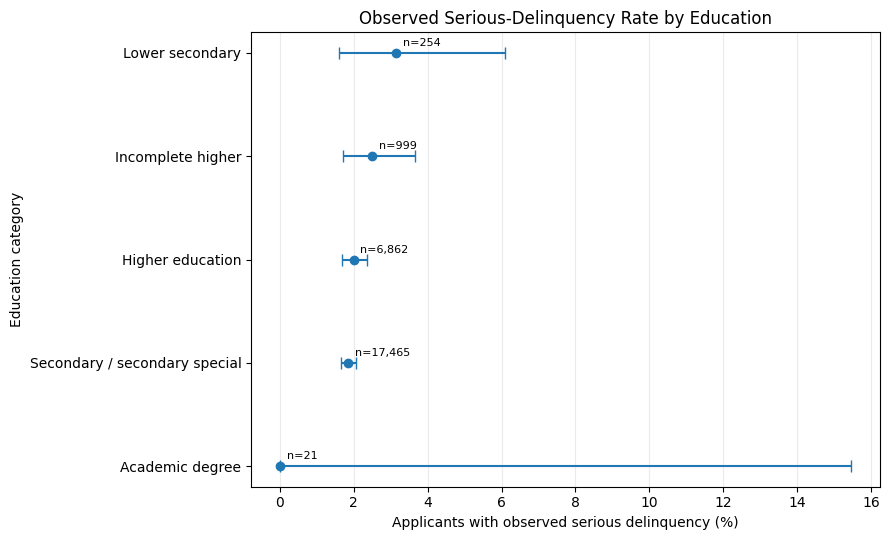

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


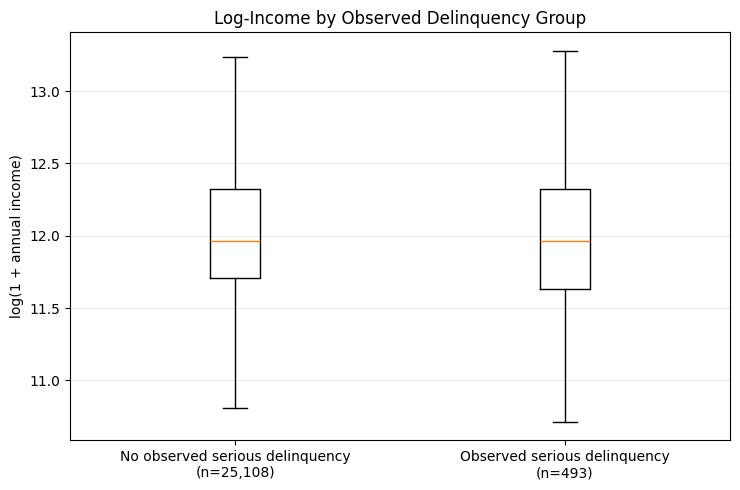

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


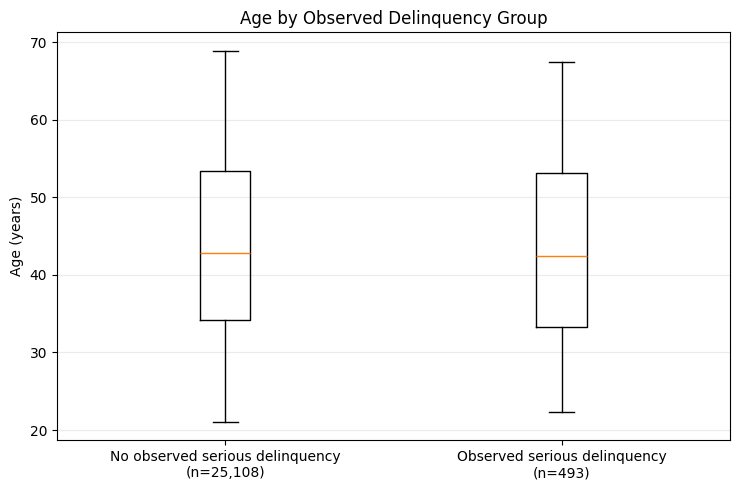

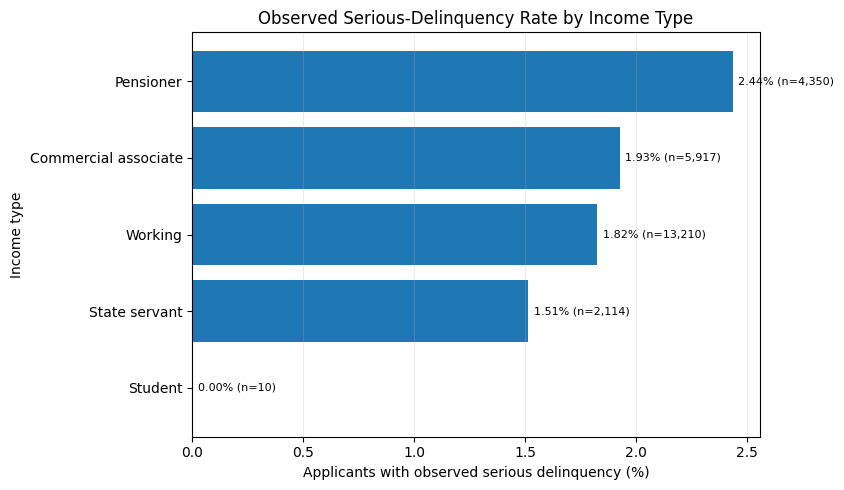

EDUCATION SUMMARY
          NAME_EDUCATION_TYPE     n  events     rate   ci_low  ci_high
              Academic degree    21       0 0.000000 0.000000 0.154639
Secondary / secondary special 17465     323 0.018494 0.016599 0.020601
             Higher education  6862     137 0.019965 0.016914 0.023553
            Incomplete higher   999      25 0.025025 0.017007 0.036682
              Lower secondary   254       8 0.031496 0.016044 0.060908

INCOME-TYPE SUMMARY
    NAME_INCOME_TYPE     n  events     rate
             Student    10       0 0.000000
       State servant  2114      32 0.015137
             Working 13210     241 0.018244
Commercial associate  5917     114 0.019267
           Pensioner  4350     106 0.024368


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [26]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportion_confint


eda = explore_df.copy()

TARGET = "EVER_SERIOUS_DELINQUENCY"


eda["AGE_YEARS"] = -eda["DAYS_BIRTH"] / 365.25
eda["LOG_INCOME"] = np.log1p(eda["AMT_INCOME_TOTAL"])
eda[TARGET] = eda[TARGET].astype(int)


# FIGURE 1: Observed delinquency rate by education


education_summary = (
    eda.groupby("NAME_EDUCATION_TYPE", observed=True)
       .agg(n=(TARGET, "size"), events=(TARGET, "sum"))
       .reset_index()
)

education_summary["rate"] = (
    education_summary["events"] / education_summary["n"]
)

ci = education_summary.apply(
    lambda row: proportion_confint(
        count=int(row["events"]),
        nobs=int(row["n"]),
        alpha=0.05,
        method="wilson"
    ),
    axis=1
)

education_summary["ci_low"] = [x[0] for x in ci]
education_summary["ci_high"] = [x[1] for x in ci]
education_summary = education_summary.sort_values("rate")

fig, ax = plt.subplots(figsize=(9, 5.5))

y = np.arange(len(education_summary))
rates = education_summary["rate"].to_numpy() * 100
lower = (
    education_summary["rate"] - education_summary["ci_low"]
).to_numpy() * 100
upper = (
    education_summary["ci_high"] - education_summary["rate"]
).to_numpy() * 100

ax.errorbar(
    rates, y,
    xerr=np.vstack([lower, upper]),
    fmt="o",
    capsize=4
)

ax.set_yticks(y)
ax.set_yticklabels(education_summary["NAME_EDUCATION_TYPE"])
ax.set_xlabel("Applicants with observed serious delinquency (%)")
ax.set_ylabel("Education category")
ax.set_title("Observed Serious-Delinquency Rate by Education")
ax.grid(axis="x", alpha=0.25)

for i, row in enumerate(education_summary.itertuples(index=False)):
    ax.annotate(
        f"n={row.n:,}",
        (row.rate * 100, i),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

fig.tight_layout()
plt.show()


# FIGURE 2: Log-income distribution by outcome


income_groups = [
    eda.loc[eda[TARGET] == 0, "LOG_INCOME"].dropna(),
    eda.loc[eda[TARGET] == 1, "LOG_INCOME"].dropna()
]

fig, ax = plt.subplots(figsize=(7.5, 5))

ax.boxplot(
    income_groups,
    tick_labels=[
        f"No observed serious delinquency\n(n={len(income_groups[0]):,})",
        f"Observed serious delinquency\n(n={len(income_groups[1]):,})"
    ],
    showfliers=False
)

ax.set_ylabel("log(1 + annual income)")
ax.set_title("Log-Income by Observed Delinquency Group")
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
plt.show()



# FIGURE 3: Age distribution by outcome


age_groups = [
    eda.loc[eda[TARGET] == 0, "AGE_YEARS"].dropna(),
    eda.loc[eda[TARGET] == 1, "AGE_YEARS"].dropna()
]

fig, ax = plt.subplots(figsize=(7.5, 5))

ax.boxplot(
    age_groups,
    tick_labels=[
        f"No observed serious delinquency\n(n={len(age_groups[0]):,})",
        f"Observed serious delinquency\n(n={len(age_groups[1]):,})"
    ],
    showfliers=False
)

ax.set_ylabel("Age (years)")
ax.set_title("Age by Observed Delinquency Group")
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
plt.show()



# FIGURE 4: Observed delinquency rate by income type


income_type_summary = (
    eda.groupby("NAME_INCOME_TYPE", observed=True)
       .agg(n=(TARGET, "size"), events=(TARGET, "sum"))
       .reset_index()
)

income_type_summary["rate"] = (
    income_type_summary["events"] / income_type_summary["n"]
)

income_type_summary = income_type_summary.sort_values("rate")

fig, ax = plt.subplots(figsize=(8.5, 5))

y = np.arange(len(income_type_summary))

ax.barh(
    y,
    income_type_summary["rate"] * 100
)

ax.set_yticks(y)
ax.set_yticklabels(income_type_summary["NAME_INCOME_TYPE"])
ax.set_xlabel("Applicants with observed serious delinquency (%)")
ax.set_ylabel("Income type")
ax.set_title("Observed Serious-Delinquency Rate by Income Type")
ax.grid(axis="x", alpha=0.25)

for i, row in enumerate(income_type_summary.itertuples(index=False)):
    ax.annotate(
        f"{row.rate * 100:.2f}% (n={row.n:,})",
        (row.rate * 100, i),
        xytext=(4, 0),
        textcoords="offset points",
        va="center",
        fontsize=8
    )

fig.tight_layout()
plt.show()



print("EDUCATION SUMMARY")
print(education_summary.to_string(index=False))

print("\nINCOME-TYPE SUMMARY")
print(income_type_summary.to_string(index=False))

Test 1: Two-Proportion Z-Test for Education

In [27]:
test_results = []

education_groups = {
    "Higher education": "Higher education",
    "Secondary education": "Secondary / secondary special"
}

g1 = confirm_df[
    confirm_df["NAME_EDUCATION_TYPE"]
    == education_groups["Higher education"]
]

g2 = confirm_df[
    confirm_df["NAME_EDUCATION_TYPE"]
    == education_groups["Secondary education"]
]

n1 = len(g1)
n2 = len(g2)

x1 = int(g1["EVER_SERIOUS_DELINQUENCY"].sum())
x2 = int(g2["EVER_SERIOUS_DELINQUENCY"].sum())

p1 = x1 / n1
p2 = x2 / n2

# H0: p1 = p2; H1: p1 != p2
z_stat, p_value = proportions_ztest(
    count=[x1, x2],
    nobs=[n1, n2],
    alternative="two-sided"
)

# Unpooled 95% confidence interval for p1 - p2
risk_difference = p1 - p2

se_diff = np.sqrt(
    p1 * (1 - p1) / n1 +
    p2 * (1 - p2) / n2
)

ci_low = risk_difference - stats.norm.ppf(0.975) * se_diff
ci_high = risk_difference + stats.norm.ppf(0.975) * se_diff

print("TEST 1: TWO-PROPORTION Z-TEST")
print("Higher-education group:", n1, "applicants")
print("Secondary-education group:", n2, "applicants")
print(f"Observed proportions: {p1:.4f} vs {p2:.4f}")
print(f"Risk difference (higher - secondary): {risk_difference:.4f}")
print(f"95% CI: [{ci_low:.4f}, {ci_high:.4f}]")
print(f"z statistic: {z_stat:.4f}")
print("Degrees of freedom: not applicable")
print(f"p-value: {p_value:.6g}")
print("Practical threshold: 0.03 absolute risk difference")

test_results.append({
    "Test": "Two-proportion z-test",
    "Statistic": z_stat,
    "df": np.nan,
    "p_raw": p_value,
    "Estimate": risk_difference,
    "CI_low": ci_low,
    "CI_high": ci_high,
    "Estimate_type": "Risk difference",
    "Threshold": 0.03
})

TEST 1: TWO-PROPORTION Z-TEST
Higher-education group: 1737 applicants
Secondary-education group: 4316 applicants
Observed proportions: 0.0196 vs 0.0183
Risk difference (higher - secondary): 0.0013
95% CI: [-0.0064, 0.0089]
z statistic: 0.3302
Degrees of freedom: not applicable
p-value: 0.741239
Practical threshold: 0.03 absolute risk difference


Test 2: Welch’s T-Test for Log-Income

In [28]:
income_df = confirm_df[
    (confirm_df["AMT_INCOME_TOTAL"] > 0) &
    confirm_df["AMT_INCOME_TOTAL"].notna()
].copy()

income_df["LOG_INCOME"] = np.log(
    income_df["AMT_INCOME_TOTAL"]
)

income_yes = income_df.loc[
    income_df["EVER_SERIOUS_DELINQUENCY"] == 1,
    "LOG_INCOME"
].to_numpy()

income_no = income_df.loc[
    income_df["EVER_SERIOUS_DELINQUENCY"] == 0,
    "LOG_INCOME"
].to_numpy()

# H0: mean log-income is equal; H1: means differ
t_stat, p_value = stats.ttest_ind(
    income_yes, income_no,
    equal_var=False,
    alternative="two-sided"
)

n_yes, n_no = len(income_yes), len(income_no)
m_yes, m_no = income_yes.mean(), income_no.mean()
v_yes, v_no = income_yes.var(ddof=1), income_no.var(ddof=1)

mean_diff = m_yes - m_no

se = np.sqrt(v_yes / n_yes + v_no / n_no)


df_welch = (
    (v_yes / n_yes + v_no / n_no) ** 2 /
    (
        (v_yes / n_yes) ** 2 / (n_yes - 1) +
        (v_no / n_no) ** 2 / (n_no - 1)
    )
)

t_critical = stats.t.ppf(0.975, df_welch)

ci_low = mean_diff - t_critical * se
ci_high = mean_diff + t_critical * se


relative_diff = np.exp(mean_diff) - 1
relative_ci_low = np.exp(ci_low) - 1
relative_ci_high = np.exp(ci_high) - 1

print("TEST 2: WELCH'S T-TEST")
print("Applicants with serious delinquency:", n_yes)
print("Applicants without observed serious delinquency:", n_no)
print(f"Mean log-income difference: {mean_diff:.4f}")
print(f"95% CI on log scale: [{ci_low:.4f}, {ci_high:.4f}]")
print(f"t statistic: {t_stat:.4f}")
print(f"Welch degrees of freedom: {df_welch:.2f}")
print(f"p-value: {p_value:.6g}")
print(f"Relative geometric-mean difference: {100*relative_diff:.2f}%")
print(
    "95% CI for relative difference: "
    f"[{100*relative_ci_low:.2f}%, {100*relative_ci_high:.2f}%]"
)
print("Practical threshold: 5% relative difference")

test_results.append({
    "Test": "Welch t-test on log-income",
    "Statistic": t_stat,
    "df": df_welch,
    "p_raw": p_value,
    "Estimate": mean_diff,
    "CI_low": ci_low,
    "CI_high": ci_high,
    "Estimate_type": "Mean log-income difference",
    "Threshold": np.log(1.05)
})

TEST 2: WELCH'S T-TEST
Applicants with serious delinquency: 123
Applicants without observed serious delinquency: 6278
Mean log-income difference: 0.0211
95% CI on log scale: [-0.0598, 0.1021]
t statistic: 0.5164
Welch degrees of freedom: 127.56
p-value: 0.606499
Relative geometric-mean difference: 2.13%
95% CI for relative difference: [-5.81%, 10.75%]
Practical threshold: 5% relative difference


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Test 3: Chi-Square Test for Income Type

In [29]:
ct_df = confirm_df.copy()

ct_df["NAME_INCOME_TYPE"] = (
    ct_df["NAME_INCOME_TYPE"]
    .fillna("Unknown")
    .astype(str)
)

contingency = pd.crosstab(
    ct_df["NAME_INCOME_TYPE"],
    ct_df["EVER_SERIOUS_DELINQUENCY"]
)

chi2_stat, p_value, df_chi, expected = chi2_contingency(
    contingency,
    correction=False
)

n = contingency.to_numpy().sum()
min_dim = min(contingency.shape[0] - 1, contingency.shape[1] - 1)

cramers_v = np.sqrt(chi2_stat / (n * min_dim))

print("TEST 3: CHI-SQUARE INDEPENDENCE")
display(contingency)

print(f"Chi-square statistic: {chi2_stat:.4f}")
print(f"Degrees of freedom: {df_chi}")
print(f"p-value: {p_value:.6g}")
print(f"Cramer's V: {cramers_v:.4f}")
print("Practical benchmark: Cramer's V = 0.10")
print("Minimum expected cell count:", expected.min())
print("Expected cells below 5:", (expected < 5).sum())

def cramers_v_from_data(data):
    tab = pd.crosstab(
        data["NAME_INCOME_TYPE"].fillna("Unknown"),
        data["EVER_SERIOUS_DELINQUENCY"]
    )

    if min(tab.shape) < 2:
        return np.nan

    chi2 = chi2_contingency(tab, correction=False)[0]
    n = tab.to_numpy().sum()
    return np.sqrt(chi2 / (n * min(tab.shape[0]-1, tab.shape[1]-1)))

rng = np.random.default_rng(SEED)
B = 500
v_boot = []

for _ in range(B):
    sample = ct_df.iloc[
        rng.integers(0, len(ct_df), len(ct_df))
    ]
    v_boot.append(cramers_v_from_data(sample))

v_boot = np.asarray(v_boot)
v_boot = v_boot[np.isfinite(v_boot)]

v_ci = np.quantile(v_boot, [0.025, 0.975])

print(f"Cramer's V: {cramers_v:.4f}")
print(f"Bootstrap 95% CI: [{v_ci[0]:.4f}, {v_ci[1]:.4f}]")

test_results.append({
    "Test": "Chi-square independence",
    "Statistic": chi2_stat,
    "df": df_chi,
    "p_raw": p_value,
    "Estimate": cramers_v,
    "CI_low": v_ci[0],
    "CI_high": v_ci[1],
    "Estimate_type": "Cramer's V",
    "Threshold": 0.10
})

TEST 3: CHI-SQUARE INDEPENDENCE


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


EVER_SERIOUS_DELINQUENCY,0,1
NAME_INCOME_TYPE,,
Commercial associate,1448,29
Pensioner,1026,24
State servant,517,5
Student,1,0
Working,3286,65


Chi-square statistic: 3.3503
Degrees of freedom: 4
p-value: 0.500995
Cramer's V: 0.0229
Practical benchmark: Cramer's V = 0.10
Minimum expected cell count: 0.01921574753944696
Expected cells below 5: 2


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Cramer's V: 0.0229
Bootstrap 95% CI: [0.0103, 0.0468]


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Test 4: Mann–Whitney U Test for Age

In [30]:
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu



confirm_df = confirm_df.copy()

if "AGE_YEARS" not in confirm_df.columns:

    if "DAYS_BIRTH" in confirm_df.columns:
        confirm_df["AGE_YEARS"] = (
            confirm_df["DAYS_BIRTH"].abs() / 365.25
        )

    elif "ID" in confirm_df.columns:


        possible_names = [
            "clean_application_df",
            "application_df",
            "application_data",
            "application",
            "app_df"
        ]

        app_df = next(
            (
                globals()[name]
                for name in possible_names
                if name in globals()
                and isinstance(globals()[name], pd.DataFrame)
                and {"ID", "DAYS_BIRTH"}.issubset(
                    globals()[name].columns
                )
            ),
            None
        )

        if app_df is None:
            raise KeyError(
                "AGE_YEARS and DAYS_BIRTH are absent from confirm_df, "
                "and no application dataframe containing ID and "
                "DAYS_BIRTH was found."
            )


        age_lookup = app_df[["ID", "DAYS_BIRTH"]].drop_duplicates(
            subset=["ID"]
        ).copy()

        age_lookup["AGE_YEARS"] = (
            age_lookup["DAYS_BIRTH"].abs() / 365.25
        )


        confirm_df = confirm_df.merge(
            age_lookup[["ID", "AGE_YEARS"]],
            on="ID",
            how="left",
            validate="many_to_one"
        )

    else:
        raise KeyError(
            "Cannot calculate age. Available columns in confirm_df:\n"
            f"{confirm_df.columns.tolist()}"
        )


target = "EVER_SERIOUS_DELINQUENCY"

if target not in confirm_df.columns:
    raise KeyError(
        f"Missing target column: {target}\n"
        f"Available columns: {confirm_df.columns.tolist()}"
    )


age_df = confirm_df.dropna(
    subset=["AGE_YEARS", target]
).copy()

age_yes = age_df.loc[
    age_df[target] == 1, "AGE_YEARS"
].to_numpy(dtype=float)

age_no = age_df.loc[
    age_df[target] == 0, "AGE_YEARS"
].to_numpy(dtype=float)

if len(age_yes) == 0 or len(age_no) == 0:
    raise ValueError(
        "At least one delinquency group has no valid age observations."
    )

print("Valid applicants:", len(age_df))
print("Applicants with observed serious delinquency:", len(age_yes))
print("Applicants without observed serious delinquency:", len(age_no))


u_stat, p_value = mannwhitneyu(
    age_yes,
    age_no,
    alternative="two-sided",
    method="asymptotic"
)

median_diff = np.median(age_yes) - np.median(age_no)


rng = np.random.default_rng(SEED)
B = 1000
median_boot = np.empty(B)

for b in range(B):
    sample_yes = rng.choice(
        age_yes, size=len(age_yes), replace=True
    )
    sample_no = rng.choice(
        age_no, size=len(age_no), replace=True
    )

    median_boot[b] = (
        np.median(sample_yes) - np.median(sample_no)
    )

age_ci_low, age_ci_high = np.quantile(
    median_boot, [0.025, 0.975]
)


print("\nTEST 4: MANN-WHITNEY U")
print(f"Median age, serious delinquency: {np.median(age_yes):.3f} years")
print(f"Median age, no serious delinquency: {np.median(age_no):.3f} years")
print(f"Median age difference: {median_diff:.3f} years")
print(
    f"Bootstrap 95% CI: "
    f"[{age_ci_low:.3f}, {age_ci_high:.3f}]"
)
print(f"U statistic: {u_stat:.4f}")
print("Degrees of freedom: not applicable")
print(f"p-value: {p_value:.6g}")
print("Practical threshold: 2 years in median age difference")


test_results[:] = [
    result for result in test_results
    if result.get("Test") != "Mann-Whitney U"
]

test_results.append({
    "Test": "Mann-Whitney U",
    "Statistic": u_stat,
    "df": np.nan,
    "p_raw": p_value,
    "Estimate": median_diff,
    "CI_low": age_ci_low,
    "CI_high": age_ci_high,
    "Estimate_type": "Median age difference (years)",
    "Threshold": 2.0
})

Valid applicants: 6401
Applicants with observed serious delinquency: 123
Applicants without observed serious delinquency: 6278

TEST 4: MANN-WHITNEY U
Median age, serious delinquency: 44.936 years
Median age, no serious delinquency: 42.464 years
Median age difference: 2.472 years
Bootstrap 95% CI: [-2.612, 5.681]
U statistic: 395876.0000
Degrees of freedom: not applicable
p-value: 0.629968
Practical threshold: 2 years in median age difference


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
